In [2]:
import os
import json
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import joblib
import tensorflow as tf

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.layers import (
    Input,
    Dense,
    Dropout,
    LSTM,
    Concatenate
)
from tensorflow.keras.callbacks import EarlyStopping

warnings.filterwarnings("ignore")

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

os.makedirs("models", exist_ok=True)
os.makedirs("results", exist_ok=True)

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
df = pd.read_csv(
    "data.csv",
    sep=";",
    encoding="utf-8-sig"
)

df.columns = (
    df.columns
    .str.replace("\ufeff", "", regex=False)
    .str.replace("\t", "", regex=False)
    .str.strip()
)

print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nDataset columns:")
print(df.columns.tolist())

print("\nTarget distribution:")
print(df["Target"].value_counts())

Dataset shape: (4424, 37)

First five rows:


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate



Dataset columns:
['Marital status', 'Application mode', 'Application order', 'Course', 'Daytime/evening attendance', 'Previous qualification', 'Previous qualification (grade)', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Admission grade', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'Age at enrollment', 'International', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)', 'Unemployment rate', 'Inflation rate', 'GDP', 'Targ

In [4]:
df = df.copy()

df = df.dropna(subset=["Target"])

df["at_risk"] = (
    df["Target"]
    .astype(str)
    .str.strip()
    .str.lower()
    .eq("dropout")
    .astype(int)
)

print("Target mapping:")
print("Dropout = 1 (At Risk)")
print("Graduate = 0 (Not At Risk)")
print("Enrolled = 0 (Not At Risk)")

print("\nTarget counts:")
print(df["at_risk"].value_counts())

print("\nRisk percentage:")
print(round(df["at_risk"].mean() * 100, 2), "%")

Target mapping:
Dropout = 1 (At Risk)
Graduate = 0 (Not At Risk)
Enrolled = 0 (Not At Risk)

Target counts:
at_risk
0    3003
1    1421
Name: count, dtype: int64

Risk percentage:
32.12 %


In [5]:
sem1 = [
    "Curricular units 1st sem (credited)",
    "Curricular units 1st sem (enrolled)",
    "Curricular units 1st sem (evaluations)",
    "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)",
    "Curricular units 1st sem (without evaluations)"
]

sem2 = [
    "Curricular units 2nd sem (credited)",
    "Curricular units 2nd sem (enrolled)",
    "Curricular units 2nd sem (evaluations)",
    "Curricular units 2nd sem (approved)",
    "Curricular units 2nd sem (grade)",
    "Curricular units 2nd sem (without evaluations)"
]

missing = [
    col for col in sem1 + sem2
    if col not in df.columns
]

if missing:
    raise ValueError(f"Missing semester columns: {missing}")

sequence_columns = sem1 + sem2

static_columns = [
    col for col in df.columns
    if col not in sequence_columns + ["Target", "at_risk"]
]

print("Semester 1 features:", len(sem1))
print("Semester 2 features:", len(sem2))
print("Static features:", len(static_columns))

print("\nStatic feature columns:")
print(static_columns)

Semester 1 features: 6
Semester 2 features: 6
Static features: 24

Static feature columns:
['Marital status', 'Application mode', 'Application order', 'Course', 'Daytime/evening attendance', 'Previous qualification', 'Previous qualification (grade)', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Admission grade', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'Age at enrollment', 'International', 'Unemployment rate', 'Inflation rate', 'GDP']


In [6]:
feature_columns = sequence_columns + static_columns

X = df[feature_columns].copy()

for col in feature_columns:
    X[col] = pd.to_numeric(X[col], errors="coerce")

X = X.replace([np.inf, -np.inf], np.nan)

y = df["at_risk"].astype(int)

print("Input features:", X.shape)
print("Target values:", y.shape)
print("Missing feature values:", int(X.isna().sum().sum()))

Input features: (4424, 36)
Target values: (4424,)
Missing feature values: 0


In [7]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

print("Training records:", len(X_train_raw))
print("Testing records:", len(X_test_raw))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training records: 3539
Testing records: 885

Training class distribution:
at_risk
0    2402
1    1137
Name: count, dtype: int64

Testing class distribution:
at_risk
0    601
1    284
Name: count, dtype: int64


In [8]:
train_medians = X_train_raw.median().fillna(0)

X_train_raw = X_train_raw.fillna(train_medians)
X_test_raw = X_test_raw.fillna(train_medians)

print("Remaining training missing values:", X_train_raw.isna().sum().sum())
print("Remaining testing missing values:", X_test_raw.isna().sum().sum())

Remaining training missing values: 0
Remaining testing missing values: 0


In [9]:
X_train_seq_raw = X_train_raw[sequence_columns].to_numpy().reshape(
    -1, 2, 6
)

X_test_seq_raw = X_test_raw[sequence_columns].to_numpy().reshape(
    -1, 2, 6
)

X_train_static_raw = X_train_raw[static_columns].to_numpy()
X_test_static_raw = X_test_raw[static_columns].to_numpy()

sc_seq = StandardScaler()
sc_sta = StandardScaler()

X_train_seq = sc_seq.fit_transform(
    X_train_seq_raw.reshape(-1, 6)
).reshape(-1, 2, 6)

X_test_seq = sc_seq.transform(
    X_test_seq_raw.reshape(-1, 6)
).reshape(-1, 2, 6)

X_train_static = sc_sta.fit_transform(X_train_static_raw)
X_test_static = sc_sta.transform(X_test_static_raw)

print("Training sequence shape:", X_train_seq.shape)
print("Testing sequence shape:", X_test_seq.shape)

print("Training static shape:", X_train_static.shape)
print("Testing static shape:", X_test_static.shape)

Training sequence shape: (3539, 2, 6)
Testing sequence shape: (885, 2, 6)
Training static shape: (3539, 24)
Testing static shape: (885, 24)


In [10]:
X_train_mlp = np.concatenate(
    [
        X_train_seq.reshape(len(X_train_seq), -1),
        X_train_static
    ],
    axis=1
)

X_test_mlp = np.concatenate(
    [
        X_test_seq.reshape(len(X_test_seq), -1),
        X_test_static
    ],
    axis=1
)

mlp_feature_names = (
    [f"{col} (Semester 1)" for col in sem1]
    + [f"{col} (Semester 2)" for col in sem2]
    + static_columns
)

print("MLP training input:", X_train_mlp.shape)
print("MLP testing input:", X_test_mlp.shape)
print("Number of MLP feature names:", len(mlp_feature_names))

MLP training input: (3539, 36)
MLP testing input: (885, 36)
Number of MLP feature names: 36


In [11]:
model = Sequential([
    Input(shape=(X_train_mlp.shape[1],)),
    Dense(128, activation="relu"),
    Dropout(0.30),
    Dense(64, activation="relu"),
    Dropout(0.20),
    Dense(32, activation="relu"),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

history_mlp = model.fit(
    X_train_mlp,
    y_train.to_numpy(),
    validation_split=0.20,
    epochs=50,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

print("MLP training completed.")

Epoch 1/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.7506 - loss: 0.5193 - val_accuracy: 0.8404 - val_loss: 0.3842
Epoch 2/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8594 - loss: 0.3620 - val_accuracy: 0.8573 - val_loss: 0.3557
Epoch 3/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8686 - loss: 0.3409 - val_accuracy: 0.8517 - val_loss: 0.3554
Epoch 4/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8700 - loss: 0.3277 - val_accuracy: 0.8602 - val_loss: 0.3486
Epoch 5/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8725 - loss: 0.3188 - val_accuracy: 0.8672 - val_loss: 0.3435
Epoch 6/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8771 - loss: 0.3165 - val_accuracy: 0.8715 - val_loss: 0.3320
Epoch 7/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8810 - loss: 0.3009 - val_accuracy: 0.8672 - val_loss: 0.3415
Epoch 8/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8795 - loss: 0.2993 - val_accuracy: 0.8743 - val_loss:

In [12]:
sequence_input = Input(shape=(2, 6), name="semester_sequence")
static_input = Input(
    shape=(X_train_static.shape[1],),
    name="static_features"
)

sequence_output = LSTM(64)(sequence_input)
sequence_output = Dropout(0.25)(sequence_output)

combined = Concatenate()([sequence_output, static_input])

combined = Dense(64, activation="relu")(combined)
combined = Dropout(0.25)(combined)
combined = Dense(32, activation="relu")(combined)

output = Dense(1, activation="sigmoid")(combined)

model_lstm = Model(
    inputs=[sequence_input, static_input],
    outputs=output
)

model_lstm.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history_lstm = model_lstm.fit(
    [X_train_seq, X_train_static],
    y_train.to_numpy(),
    validation_split=0.20,
    epochs=50,
    batch_size=32,
    callbacks=[
        EarlyStopping(
            monitor="val_loss",
            patience=8,
            restore_best_weights=True
        )
    ],
    verbose=1
)

print("LSTM training completed.")

Epoch 1/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.7450 - loss: 0.5318 - val_accuracy: 0.8489 - val_loss: 0.3880
Epoch 2/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8622 - loss: 0.3615 - val_accuracy: 0.8517 - val_loss: 0.3570
Epoch 3/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8693 - loss: 0.3371 - val_accuracy: 0.8545 - val_loss: 0.3467
Epoch 4/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8704 - loss: 0.3224 - val_accuracy: 0.8588 - val_loss: 0.3393
Epoch 5/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8718 - loss: 0.3137 - val_accuracy: 0.8644 - val_loss: 0.3385
Epoch 6/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8757 - loss: 0.3090 - val_accuracy: 0.8644 - val_loss: 0.3351
Epoch 7/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8848 - loss: 0.3007 - val_accuracy: 0.8644 - val_loss: 0.3375
Epoch 8/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8795 - loss: 0.2982 - val_accuracy: 0.8630 - val_loss:


MLP Model
Accuracy: 0.8701
Precision: 0.8894
Recall: 0.6796
F1-score: 0.7705

Classification report:
              precision    recall  f1-score   support

 Not At Risk       0.86      0.96      0.91       601
     At Risk       0.89      0.68      0.77       284

    accuracy                           0.87       885
   macro avg       0.88      0.82      0.84       885
weighted avg       0.87      0.87      0.86       885



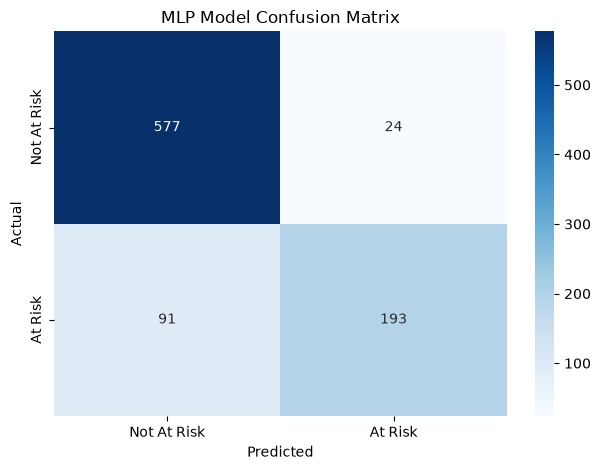


LSTM Model
Accuracy: 0.878
Precision: 0.8929
Recall: 0.7042
F1-score: 0.7874

Classification report:
              precision    recall  f1-score   support

 Not At Risk       0.87      0.96      0.91       601
     At Risk       0.89      0.70      0.79       284

    accuracy                           0.88       885
   macro avg       0.88      0.83      0.85       885
weighted avg       0.88      0.88      0.87       885



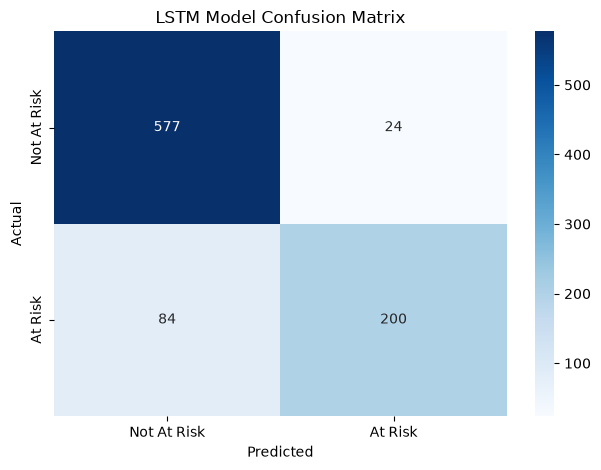

In [13]:
def evaluate_model(name, y_true, probabilities):
    predictions = (probabilities.ravel() >= 0.5).astype(int)

    print(f"\n{'=' * 45}")
    print(name)
    print(f"{'=' * 45}")

    print("Accuracy:", round(accuracy_score(y_true, predictions), 4))
    print("Precision:", round(
        precision_score(y_true, predictions, zero_division=0), 4
    ))
    print("Recall:", round(
        recall_score(y_true, predictions, zero_division=0), 4
    ))
    print("F1-score:", round(
        f1_score(y_true, predictions, zero_division=0), 4
    ))

    print("\nClassification report:")
    print(classification_report(
        y_true,
        predictions,
        target_names=["Not At Risk", "At Risk"],
        zero_division=0
    ))

    cm = confusion_matrix(y_true, predictions)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Not At Risk", "At Risk"],
        yticklabels=["Not At Risk", "At Risk"]
    )

    plt.title(f"{name} Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()

    return predictions


y_pred_mlp_prob = model.predict(X_test_mlp, verbose=0)
y_pred_lstm_prob = model_lstm.predict(
    [X_test_seq, X_test_static],
    verbose=0
)

y_pred_mlp = evaluate_model(
    "MLP Model",
    y_test,
    y_pred_mlp_prob
)

y_pred_lstm = evaluate_model(
    "LSTM Model",
    y_test,
    y_pred_lstm_prob
)

In [14]:
results = pd.DataFrame([
    {
        "Model": "MLP",
        "Accuracy": accuracy_score(y_test, y_pred_mlp),
        "Precision": precision_score(
            y_test, y_pred_mlp, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred_mlp, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred_mlp, zero_division=0
        )
    },
    {
        "Model": "LSTM",
        "Accuracy": accuracy_score(y_test, y_pred_lstm),
        "Precision": precision_score(
            y_test, y_pred_lstm, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred_lstm, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred_lstm, zero_division=0
        )
    }
])

display(results.round(4))

results.to_csv("models/model_results.csv", index=False)

,Model,Accuracy,Precision,Recall,F1 Score
0,MLP,0.8701,0.8894,0.6796,0.7705
1,LSTM,0.8780,0.8929,0.7042,0.7874


In [15]:
background_size = min(30, len(X_train_mlp))
explain_size = min(20, len(X_test_mlp))

background_mlp = shap.sample(
    X_train_mlp,
    background_size,
    random_state=SEED
)

samples_mlp = X_test_mlp[:explain_size]

explainer_mlp = shap.KernelExplainer(
    lambda data: model.predict(
        np.asarray(data, dtype=np.float32),
        verbose=0
    ).reshape(-1),
    background_mlp,
    feature_names=mlp_feature_names
)

shap_values_mlp = explainer_mlp.shap_values(
    samples_mlp,
    nsamples=100
)

print("MLP SHAP explanations generated.")

  0%|          | 0/20 [00:00<?, ?it/s]

MLP SHAP explanations generated.


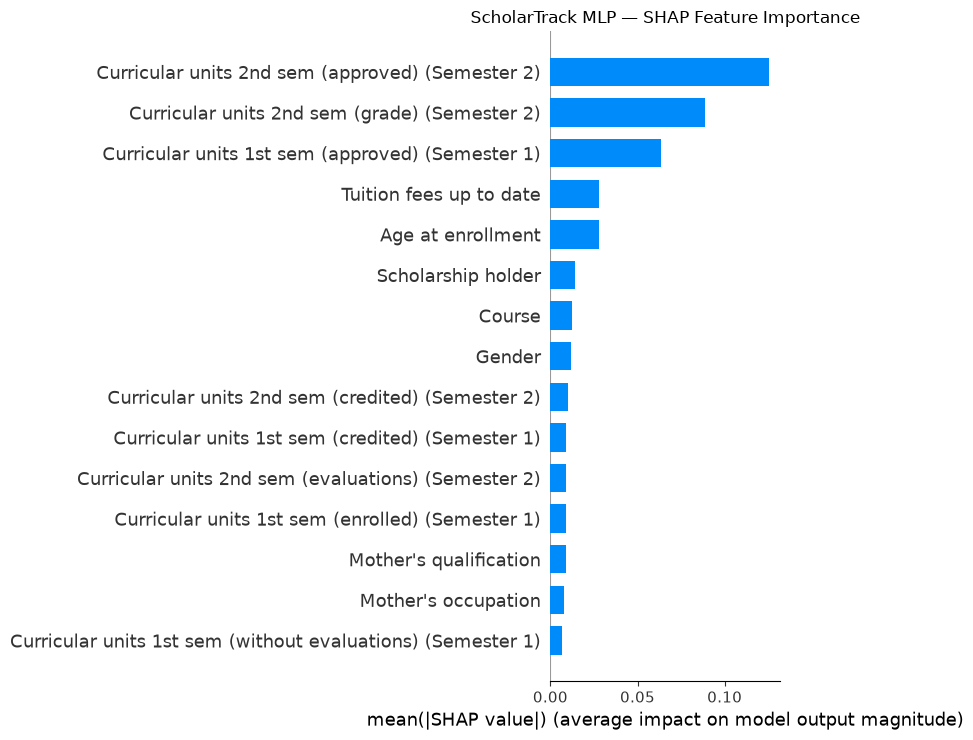

In [16]:
values_mlp = np.asarray(shap_values_mlp)

if values_mlp.ndim == 3:
    values_mlp = values_mlp[:, :, 0]

values_mlp = values_mlp.reshape(
    len(samples_mlp),
    len(mlp_feature_names)
)

plt.figure()

shap.summary_plot(
    values_mlp,
    samples_mlp,
    feature_names=mlp_feature_names,
    plot_type="bar",
    max_display=15,
    show=False
)

plt.title("ScholarTrack MLP — SHAP Feature Importance")
plt.tight_layout()
plt.savefig("results/mlp_shap_importance.png", bbox_inches="tight")
plt.show()

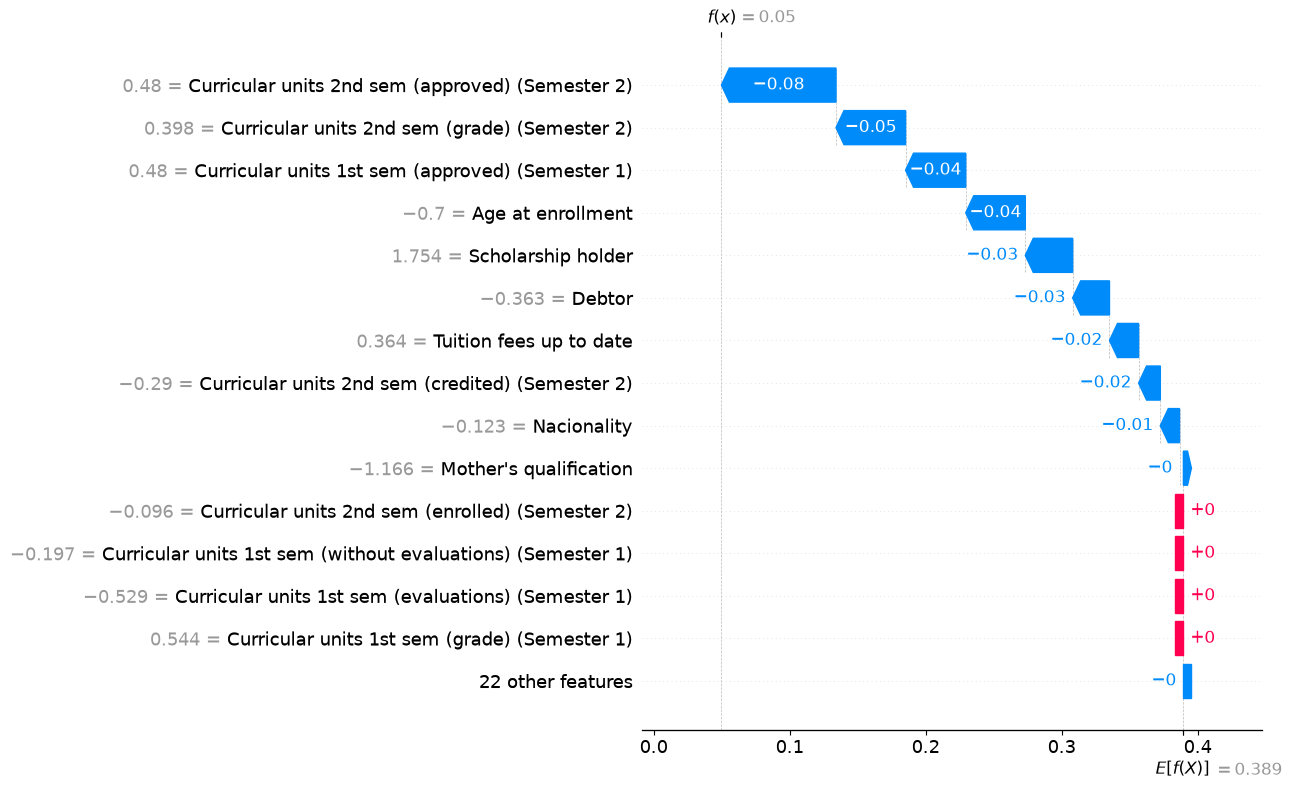

MLP predicted risk probability: 0.0498
MLP predicted class: Not At Risk


In [17]:
student_index = 0

base_value_mlp = np.asarray(
    explainer_mlp.expected_value
).reshape(-1)[0]

mlp_explanation = shap.Explanation(
    values=values_mlp[student_index],
    base_values=float(base_value_mlp),
    data=samples_mlp[student_index],
    feature_names=mlp_feature_names
)

shap.plots.waterfall(mlp_explanation, max_display=15)

mlp_risk = float(
    model.predict(
        samples_mlp[student_index:student_index + 1],
        verbose=0
    )[0, 0]
)

print("MLP predicted risk probability:", round(mlp_risk, 4))
print("MLP predicted class:", "At Risk" if mlp_risk >= 0.5 else "Not At Risk")

In [18]:
def predict_lstm_from_combined(data):
    data = np.asarray(data, dtype=np.float32)

    sequence_size = 12

    sequence_part = data[:, :sequence_size]
    static_part = data[:, sequence_size:]

    sequence_part = sequence_part.reshape(-1, 2, 6)

    return model_lstm.predict(
        [sequence_part, static_part],
        verbose=0
    ).reshape(-1)


background_lstm = shap.sample(
    X_train_mlp,
    background_size,
    random_state=SEED
)

samples_lstm = X_test_mlp[:explain_size]

explainer_lstm = shap.KernelExplainer(
    predict_lstm_from_combined,
    background_lstm,
    feature_names=mlp_feature_names
)

shap_values_lstm = explainer_lstm.shap_values(
    samples_lstm,
    nsamples=100
)

print("LSTM SHAP explanations generated.")

  0%|          | 0/20 [00:00<?, ?it/s]

LSTM SHAP explanations generated.


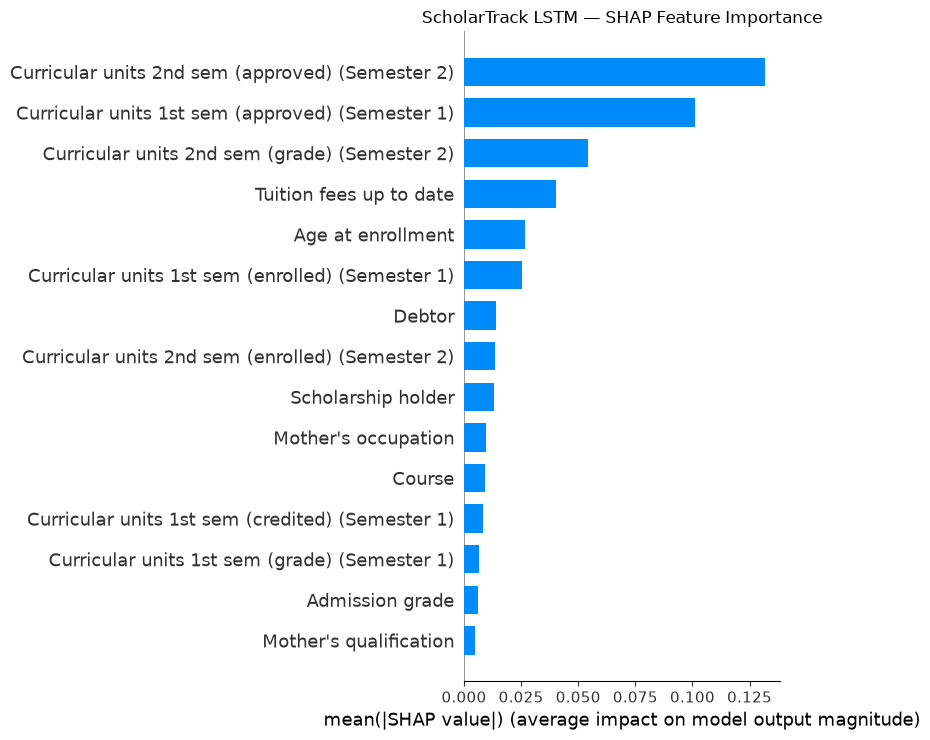

In [19]:
values_lstm = np.asarray(shap_values_lstm)

if values_lstm.ndim == 3:
    values_lstm = values_lstm[:, :, 0]

values_lstm = values_lstm.reshape(
    len(samples_lstm),
    len(mlp_feature_names)
)

plt.figure()

shap.summary_plot(
    values_lstm,
    samples_lstm,
    feature_names=mlp_feature_names,
    plot_type="bar",
    max_display=15,
    show=False
)

plt.title("ScholarTrack LSTM — SHAP Feature Importance")
plt.tight_layout()
plt.savefig("results/lstm_shap_importance.png", bbox_inches="tight")
plt.show()

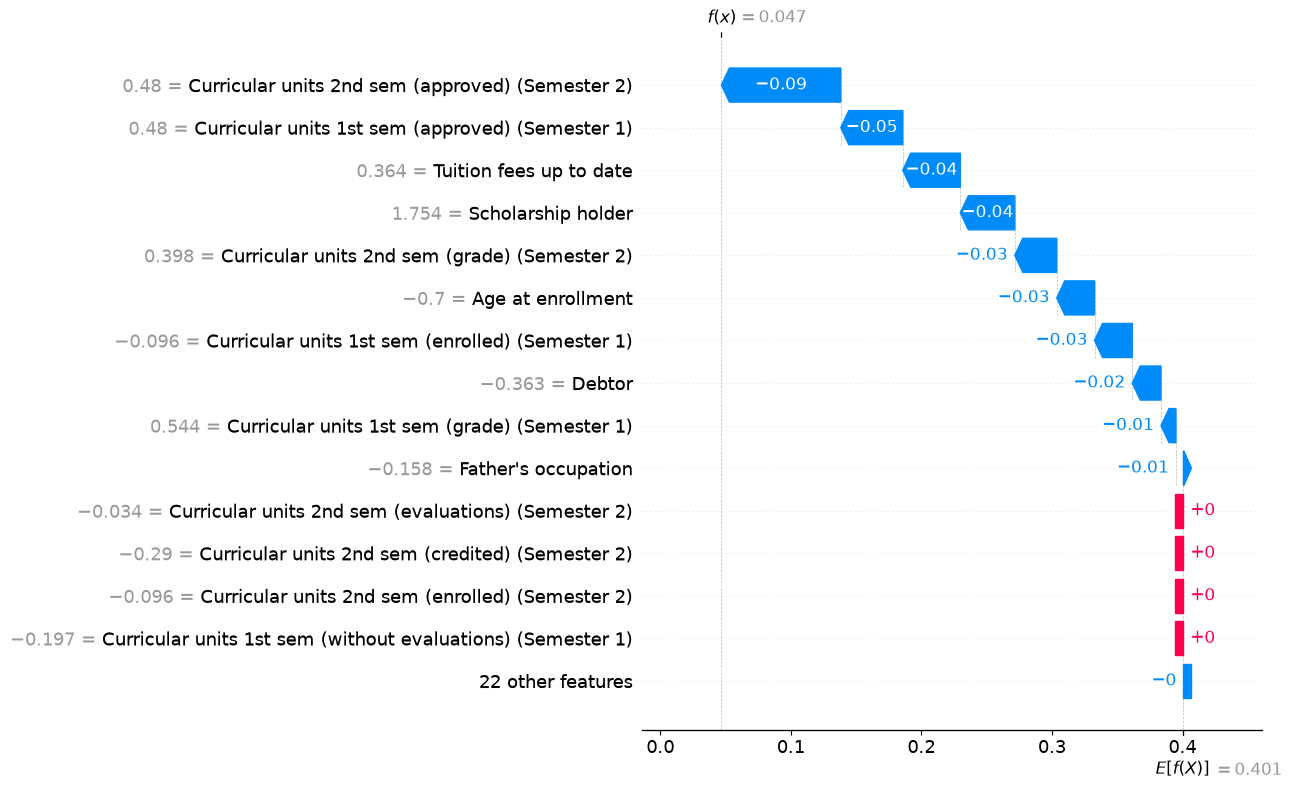

LSTM predicted risk probability: 0.0468
LSTM predicted class: Not At Risk


In [20]:
student_index = 0

base_value_lstm = np.asarray(
    explainer_lstm.expected_value
).reshape(-1)[0]

lstm_explanation = shap.Explanation(
    values=values_lstm[student_index],
    base_values=float(base_value_lstm),
    data=samples_lstm[student_index],
    feature_names=mlp_feature_names
)

shap.plots.waterfall(lstm_explanation, max_display=15)

lstm_risk = float(
    predict_lstm_from_combined(
        samples_lstm[student_index:student_index + 1]
    )[0]
)

print("LSTM predicted risk probability:", round(lstm_risk, 4))
print("LSTM predicted class:", "At Risk" if lstm_risk >= 0.5 else "Not At Risk")

In [21]:
from pathlib import Path

models_dir = Path("models")
models_dir.mkdir(exist_ok=True)

model.save(models_dir / "model.keras")
model_lstm.save(models_dir / "model_lstm.keras")

joblib.dump(sc_seq, models_dir / "sc_seq.pkl")
joblib.dump(sc_sta, models_dir / "sc_sta.pkl")
joblib.dump(train_medians, models_dir / "train_medians.pkl")

schema = {
    "sem1": sem1,
    "sem2": sem2,
    "units": sequence_columns,
    "static": static_columns,
    "target": "Target",
    "risk_column": "at_risk",
    "risk_mapping": {
        "Dropout": 1,
        "Graduate": 0,
        "Enrolled": 0
    },
    "threshold": 0.5,
    "mlp_feature_names": mlp_feature_names
}

with open(models_dir / "columns.json", "w", encoding="utf-8") as file:
    json.dump(schema, file, indent=4)

mlp_importance = pd.DataFrame({
    "Feature": mlp_feature_names,
    "Mean Absolute SHAP": np.abs(values_mlp).mean(axis=0)
}).sort_values("Mean Absolute SHAP", ascending=False)

lstm_importance = pd.DataFrame({
    "Feature": mlp_feature_names,
    "Mean Absolute SHAP": np.abs(values_lstm).mean(axis=0)
}).sort_values("Mean Absolute SHAP", ascending=False)

mlp_importance.to_csv("results/mlp_shap_values.csv", index=False)
lstm_importance.to_csv("results/lstm_shap_values.csv", index=False)

print("All models and preprocessing files saved.")
print("\nSaved files:")

for path in sorted(models_dir.iterdir()):
    print(path)

All models and preprocessing files saved.

Saved files:
models\columns.json
models\model.keras
models\model_lstm.keras
models\model_results.csv
models\sc_seq.pkl
models\sc_sta.pkl
models\train_medians.pkl


In [22]:
print("TOP 10 MLP FEATURES")
display(mlp_importance.head(10))

print("TOP 10 LSTM FEATURES")
display(lstm_importance.head(10))

TOP 10 MLP FEATURES


,Feature,Mean Absolute SHAP
9,Curricular units 2nd sem (approved) (Semester 2),0.125469
10,Curricular units 2nd sem (grade) (Semester 2),0.088465
3,Curricular units 1st sem (approved) (Semester 1),0.063621
28,Tuition fees up to date,0.028094
31,Age at enrollment,0.027908
30,Scholarship holder,0.013894
15,Course,0.012613
29,Gender,0.011556
6,Curricular units 2nd sem (credited) (Semester 2),0.009874
0,Curricular units 1st sem (credited) (Semester 1),0.009065


TOP 10 LSTM FEATURES


,Feature,Mean Absolute SHAP
9,Curricular units 2nd sem (approved) (Semester 2),0.131727
3,Curricular units 1st sem (approved) (Semester 1),0.101038
10,Curricular units 2nd sem (grade) (Semester 2),0.054322
28,Tuition fees up to date,0.040118
31,Age at enrollment,0.026668
1,Curricular units 1st sem (enrolled) (Semester 1),0.025487
27,Debtor,0.013822
7,Curricular units 2nd sem (enrolled) (Semester 2),0.013524
30,Scholarship holder,0.013265
22,Mother's occupation,0.009529


In [23]:
results_dir = Path("results")
results_dir.mkdir(exist_ok=True)

mlp_test_prob = model.predict(X_test_mlp, verbose=0).ravel()

lstm_test_prob = model_lstm.predict(
    [X_test_seq, X_test_static],
    verbose=0
).ravel()

test_results = pd.DataFrame({
    "actual": np.asarray(y_test).astype(int),
    "mlp_probability": mlp_test_prob,
    "lstm_probability": lstm_test_prob
})

test_results.to_csv(
    results_dir / "test_predictions.csv",
    index=False
)

print("Saved held-out test predictions to results/test_predictions.csv")

Saved held-out test predictions to results/test_predictions.csv
